> **Uyarı:** Bu içerik, SCÜ Şarkışla UBYO Doğal Dil İşleme dersi kapsamında tamamen eğitim amaçlı çevrilmiş ve derlenmiştir. Orijinal dokümantasyon kaynakları (Hugging Face LLM Course, Transformers, Datasets, Tokenizers kütüphaneleri) kendi orijinal lisanslarına (Apache 2.0, MIT, CC-BY 4.0) tabidir. Bu çalışmanın hiçbir ticari amacı yoktur.

# Bölüm 6 Uygulaması: 🤗 Tokenizers ile Türkçe Tokenizer İnşası

Bu notebook, Hugging Face LLM Course **Bölüm 6**'da anlatılan her adımı **Türkçe bir derlem** üzerinde uygular. Kursun giriş kısmındaki temel fikir şudur: *Başka bir dil için eğitilmiş bir tokenizer, yeni dilde verimsiz çalışır.* Türkçe eklemeli (agglutinative) bir dil olduğu için bu fikri göstermek için ideal bir örnektir.

| # | Kısım | Kursta karşılığı |
|---|---|---|
| 1 | Kurulum | – |
| 2 | Türkçe derlem ve üreteç (generator) | 6.2 |
| 3 | Normalizasyon ve ön-tokenizasyon | 6.5 |
| 4 | Sıfırdan WordPiece (BERT tarzı) | 6.7, 6.9 |
| 5 | Sıfırdan BPE (GPT-2 tarzı) | 6.6, 6.9 |
| 6 | Sıfırdan Unigram (XLNet tarzı) | 6.8, 6.9 |
| 7 | Üç algoritmanın karşılaştırılması | 6.5 (genel bakış tablosu) |
| 8 | Hızlı tokenizer'ın süper güçleri: offset ve kelime eşleme | 6.3 |
| 9 | 🤗 Transformers'a sarmalama, padding, stride | 6.4, 6.9 |
| 10 | (Opsiyonel) `train_new_from_iterator` ile GPT-2'den Türkçe tokenizer | 6.2 |

**Veri:** [UD Turkish-BOUN](https://github.com/UniversalDependencies/UD_Turkish-BOUN) ağaç bankasındaki cümleler (CC BY-SA 4.0). Dosyalar GitHub'dan doğrudan indirilir; Hugging Face hesabı gerekmez. 4–9. kısımlar tamamen çevrimdışı (offline) da çalışır.

## 1. Kurulum

In [1]:
# Colab'da ve yeni bir sanal ortamda gerekli paketleri kurar (zaten kuruluysa hızlıca geçer)
%pip install -q "tokenizers>=0.15" "transformers>=4.40" matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, unicodedata, urllib.request
from collections import Counter

import matplotlib.pyplot as plt
import tokenizers, transformers
from tokenizers import (Tokenizer, Regex, decoders, models, normalizers,
                        pre_tokenizers, processors, trainers)

print("tokenizers  :", tokenizers.__version__)
print("transformers:", transformers.__version__)

# Grafiklerde kullanılan renkler (renk körlüğü için doğrulanmış palet)
RENK = {"WordPiece": "#2a78d6", "BPE": "#eb6834", "Unigram": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


tokenizers  : 0.23.3
transformers: 5.21.0


## 2. Türkçe derlem ve üreteç (generator)

Kursun 6.2 kısmında olduğu gibi derlemi bellekte tek bir dev liste olarak tutmak yerine, tokenizer'a **1.000 cümlelik yığınlar** veren bir üreteç fonksiyonu kullanacağız. Büyük derlemlerde RAM'in dolmasını bu sayede engelleriz.

In [3]:
VERI_DIZINI = "veri"
UD_URL = "https://raw.githubusercontent.com/UniversalDependencies/{repo}/master/{dosya}"

def ud_indir(repo, dosya):
    # Dosyayı bir kez indirir, sonraki çalıştırmalarda diskteki kopyayı kullanır
    os.makedirs(VERI_DIZINI, exist_ok=True)
    yol = os.path.join(VERI_DIZINI, dosya)
    if not os.path.exists(yol):
        urllib.request.urlretrieve(UD_URL.format(repo=repo, dosya=dosya), yol)
    return yol

def cumleleri_oku(yol):
    # CoNLL-U dosyasındaki '# text = ...' satırları ham cümleleri içerir
    with open(yol, encoding="utf-8") as f:
        return [s[len("# text = "):].strip() for s in f if s.startswith("# text = ")]

tr_egitim = cumleleri_oku(ud_indir("UD_Turkish-BOUN", "tr_boun-ud-train.conllu"))
tr_test   = cumleleri_oku(ud_indir("UD_Turkish-BOUN", "tr_boun-ud-test.conllu"))

print(f"Eğitim cümlesi: {len(tr_egitim):,} | Test cümlesi: {len(tr_test):,}")
print(f"Eğitimdeki kelime sayısı: {sum(len(c.split()) for c in tr_egitim):,}")
for c in tr_egitim[:3]:
    print("  •", c)

Eğitim cümlesi: 7,803 | Test cümlesi: 979
Eğitimdeki kelime sayısı: 81,063
  • 1936 yılındayız.
  • Adeta kendimden geçmiş bir haldeyim.
  • O nasıl derse desin uğraştığı sanatın kendisine emanet olduğunu söyleyen üstadları vardı.


In [4]:
def get_training_corpus(cumleler=tr_egitim, yigin=1000):
    # Kurstaki gibi: her seferinde 1000 cümlelik bir liste döndüren üreteç
    for i in range(0, len(cumleler), yigin):
        yield cumleler[i : i + yigin]

# Üreteçler yalnızca bir kez tüketilebilir; bu yüzden her eğitimde fonksiyonu yeniden çağırıyoruz
gen = get_training_corpus()
print("İlk yığının uzunluğu:", len(next(gen)))
print("Toplam yığın sayısı :", 1 + sum(1 for _ in gen))

İlk yığının uzunluğu: 1000
Toplam yığın sayısı : 8


## 3. Normalizasyon ve ön-tokenizasyon

Tokenizer, metni alt kelimelere bölmeden önce iki adım uygular: **normalizasyon** (temizlik) ve **ön-tokenizasyon** (kelimelere bölme). Aşağıda Türkçe bir cümle üzerinde farklı seçenekleri karşılaştırıyoruz.

> ⚠️ **Türkçe için kritik nokta:** Unicode'un standart küçük harfe çevirme kuralı Türkçe'yi bilmez. `I` harfini `i` yapar (Türkçede doğrusu `ı`) ve `İ` harfini iki karakterlik `i̇` dizisine (i + birleşik nokta U+0307) dönüştürür. Bu yüzden kendi Türkçe normalizer'ımızı kuracağız. Bu konunun etkilerini **red-team** çalışmasında ayrıntılı olarak ölçtük.

In [5]:
ornek = "IŞIK ve İSTANBUL'da  çok güzel bir gün!"

bert_norm = normalizers.BertNormalizer(lowercase=True)          # bert-base-uncased'in kullandığı normalizer
standart  = normalizers.Sequence([normalizers.NFKC(), normalizers.Lowercase()])
turkce    = normalizers.Sequence([
    normalizers.NFKC(),
    normalizers.Replace(Regex("[​‌‍⁠﻿]"), ""),  # görünmez karakterleri sil
    normalizers.Replace("I", "ı"),                                         # Türkçe büyük/küçük harf kuralı
    normalizers.Replace("İ", "i"),
    normalizers.Lowercase(),
])

print("Orijinal         :", ornek)
for ad, n in [("BertNormalizer", bert_norm), ("NFKC + Lowercase", standart), ("Türkçe normalizer", turkce)]:
    sonuc = n.normalize_str(ornek)
    print(f"{ad:17}: {sonuc!r}  (uzunluk {len(sonuc)})")

print("\n'İ'.lower() karakter kodları:", [f"U+{ord(c):04X}" for c in "İ".lower()])

Orijinal         : IŞIK ve İSTANBUL'da  çok güzel bir gün!
BertNormalizer   : "isik ve istanbul'da  cok guzel bir gun!"  (uzunluk 39)
NFKC + Lowercase : "işik ve i̇stanbul'da  çok güzel bir gün!"  (uzunluk 40)
Türkçe normalizer: "ışık ve istanbul'da  çok güzel bir gün!"  (uzunluk 39)

'İ'.lower() karakter kodları: ['U+0069', 'U+0307']


In [6]:
print("Cümle:", repr(ornek), "\n")
for ad, pt in [("BertPreTokenizer (BERT)", pre_tokenizers.BertPreTokenizer()),
               ("ByteLevel (GPT-2)",       pre_tokenizers.ByteLevel(add_prefix_space=False)),
               ("Metaspace (SentencePiece)", pre_tokenizers.Metaspace())]:
    print(f"{ad}:")
    print("  ", pt.pre_tokenize_str(ornek), "\n")

Cümle: "IŞIK ve İSTANBUL'da  çok güzel bir gün!" 

BertPreTokenizer (BERT):
   [('IŞIK', (0, 4)), ('ve', (5, 7)), ('İSTANBUL', (8, 16)), ("'", (16, 17)), ('da', (17, 19)), ('çok', (21, 24)), ('güzel', (25, 30)), ('bir', (31, 34)), ('gün', (35, 38)), ('!', (38, 39))] 

ByteLevel (GPT-2):
   [('IÅŀIK', (0, 4)), ('Ġve', (4, 7)), ('ĠÄ°STANBUL', (7, 16)), ("'d", (16, 18)), ('a', (18, 19)), ('Ġ', (19, 20)), ('ĠÃ§ok', (20, 24)), ('ĠgÃ¼zel', (24, 30)), ('Ġbir', (30, 34)), ('ĠgÃ¼n', (34, 38)), ('!', (38, 39))] 

Metaspace (SentencePiece):
   [('▁IŞIK', (0, 4)), ('▁ve', (4, 7)), ("▁İSTANBUL'da", (7, 19)), ('▁', (19, 20)), ('▁çok', (20, 24)), ('▁güzel', (24, 30)), ('▁bir', (30, 34)), ('▁gün!', (34, 39))] 



**Gözlem:** BERT ön-tokenizer'ı çift boşluğu ve noktalama işaretlerini ayırıp boşlukları atar. GPT-2'nin `ByteLevel` ön-tokenizer'ı Türkçe harfleri bayt dizilerine çevirir (örneğin `Ş` → `Åŀ`); bu yüzden çıktı okunaksız görünür ama hiçbir karakter kaybolmaz. `Metaspace` ise boşlukları `▁` ile korur ve noktalamadan bölmez.

## 4. Sıfırdan WordPiece tokenizer (BERT tarzı)

Kursun 6.9 kısmındaki adımları izliyoruz: **model → normalizer → ön-tokenizer → eğitici (trainer) → son işlemci (post-processor) → çözücü (decoder)**. Tek fark, normalizer olarak 3. kısımdaki Türkçe normalizer'ı kullanmamız.

In [7]:
VOCAB = 8000   # küçük derlem için makul bir kelime dağarcığı boyutu

wp_tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
wp_tok.normalizer = turkce
wp_tok.pre_tokenizer = pre_tokenizers.BertPreTokenizer()

ozel = ["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"]
wp_trainer = trainers.WordPieceTrainer(vocab_size=VOCAB, special_tokens=ozel, show_progress=False)
wp_tok.train_from_iterator(get_training_corpus(), trainer=wp_trainer)

cls_id, sep_id = wp_tok.token_to_id("[CLS]"), wp_tok.token_to_id("[SEP]")
wp_tok.post_processor = processors.TemplateProcessing(
    single="[CLS]:0 $A:0 [SEP]:0",
    pair="[CLS]:0 $A:0 [SEP]:0 $B:1 [SEP]:1",
    special_tokens=[("[CLS]", cls_id), ("[SEP]", sep_id)],
)
wp_tok.decoder = decoders.WordPiece(prefix="##")

enc = wp_tok.encode("Kitaplarımızdan birini okudun mu?", "Evet, dün akşam bitirdim.")
print("Kelime dağarcığı:", wp_tok.get_vocab_size())
print("Token'lar :", enc.tokens)
print("Tip ID'ler:", enc.type_ids)
print("Çözülmüş  :", wp_tok.decode(enc.ids))

Kelime dağarcığı: 8000
Token'lar : ['[CLS]', 'kitapları', '##mızdan', 'birini', 'oku', '##dun', 'mu', '?', '[SEP]', 'evet', ',', 'dün', 'akşam', 'bitir', '##dim', '.', '[SEP]']
Tip ID'ler: [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1]
Çözülmüş  : kitaplarımızdan birini okudun mu? evet, dün akşam bitirdim.


## 5. Sıfırdan BPE tokenizer (GPT-2 tarzı)

GPT-2 normalizer kullanmaz ve **bayt düzeyinde BPE** kullandığı için `[UNK]` token'ına ihtiyaç duymaz. Başlangıç alfabesine 256 baytın tamamını ekliyoruz; böylece eğitimde hiç görülmemiş bir karakter (emoji, Kiril harfi vb.) bile kaybolmaz.

In [8]:
bpe_tok = Tokenizer(models.BPE())
bpe_tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe_trainer = trainers.BpeTrainer(vocab_size=VOCAB, special_tokens=["<|endoftext|>"],
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
                                  show_progress=False)
bpe_tok.train_from_iterator(get_training_corpus(), trainer=bpe_trainer)
bpe_tok.post_processor = processors.ByteLevel(trim_offsets=False)
bpe_tok.decoder = decoders.ByteLevel()

def okunur(tok, metin):
    # Bayt düzeyindeki token'ları (ör. 'Ä±') okunabilir parçalara çevirir
    return [tok.decode([i]) for i in tok.encode(metin).ids]

cumle = "Kitaplarımızdan birini okudun mu? 🙂"
print("Ham token'lar :", bpe_tok.encode(cumle).tokens)
print("Okunur parçalar:", okunur(bpe_tok, cumle))
print("Geri çözülmüş  :", bpe_tok.decode(bpe_tok.encode(cumle).ids))

Ham token'lar : ['Kitap', 'larÄ±mÄ±z', 'dan', 'Ġbirini', 'Ġoku', 'dun', 'Ġmu', '?', 'Ġ', 'ð', 'Ł', 'Ļ', 'Ĥ']
Okunur parçalar: ['Kitap', 'larımız', 'dan', ' birini', ' oku', 'dun', ' mu', '?', ' ', '�', '�', '�', '�']
Geri çözülmüş  : Kitaplarımızdan birini okudun mu? 🙂


**Gözlem:** Emoji 4 bayttan oluşur; tek bir bayt kendi başına geçerli bir karakter olmadığı için tek tek çözüldüğünde `�` görünür. Ancak bütün dizi çözüldüğünde emoji eksiksiz geri gelir: Bayt düzeyinde BPE hiçbir karakteri `[UNK]` yapmaz. Ayrıca `"Kitap"` kelimesi cümle başında olduğu için tek token, cümle içinde ise (`"Ġkitap"`) farklı bir token'dır. GPT-2 tarzı tokenizer'lar boşluğu kelimenin parçası olarak öğrenir.

## 6. Sıfırdan Unigram tokenizer (XLNet / SentencePiece tarzı)

Unigram, BPE ve WordPiece'in tersine **büyük bir kelime dağarcığıyla başlar ve budayarak** küçültür. SentencePiece gibi boşlukları `▁` ile korur; bu yüzden tokenizasyonu geri çevrilebilirdir (reversible).

In [9]:
uni_tok = Tokenizer(models.Unigram())
uni_tok.normalizer = normalizers.NFKC()   # SentencePiece'in varsayılanı gibi; büyük/küçük harf korunur
uni_tok.pre_tokenizer = pre_tokenizers.Metaspace()
uni_trainer = trainers.UnigramTrainer(vocab_size=VOCAB, special_tokens=["<cls>", "<sep>", "<unk>", "<pad>", "<mask>"],
                                      unk_token="<unk>", show_progress=False)
uni_tok.train_from_iterator(get_training_corpus(), trainer=uni_trainer)
uni_tok.decoder = decoders.Metaspace()

enc = uni_tok.encode("Kitaplarımızdan birini okudun mu?")
print("Token'lar   :", enc.tokens)
print("Geri çözülmüş:", uni_tok.decode(enc.ids))

Token'lar   : ['▁Kitap', 'larımız', 'dan', '▁bir', 'ini', '▁okudu', 'n', '▁mu?']
Geri çözülmüş: Kitaplarımızdan birini okudun mu?


## 7. Üç algoritmanın karşılaştırılması

Aynı Türkçe derlemde, aynı kelime dağarcığı boyutuyla eğitilen üç tokenizer'ı karşılaştırıyoruz. **Doğurganlık (fertility)** ölçütü, kelime başına düşen ortalama token sayısıdır. Değer ne kadar düşükse tokenizer o kadar verimlidir: Aynı metin daha az token'la temsil edilir ve modelin bağlam penceresinde daha fazla bilgi yer alır.

In [10]:
tokenizerlar = {"WordPiece": wp_tok, "BPE": bpe_tok, "Unigram": uni_tok}
UNK = {"WordPiece": "[UNK]", "Unigram": "<unk>", "BPE": None}

def dogurganlik(tok, cumleler):
    kelime = sum(len(c.split()) for c in cumleler)
    token = sum(len(e.tokens) for e in tok.encode_batch(cumleler, add_special_tokens=False))
    return token / kelime

uzun_kelime = "Çekoslovakyalılaştıramadıklarımızdanmışsınız"
print(f"{'Algoritma':10} {'Doğurganlık':>12} {'UNK oranı':>10}   '{uzun_kelime}'")
sonuclar = {}
for ad, tok in tokenizerlar.items():
    encs = tok.encode_batch(tr_test, add_special_tokens=False)
    n = sum(len(e.tokens) for e in encs)
    unk = sum(e.tokens.count(UNK[ad]) for e in encs) if UNK[ad] else 0
    sonuclar[ad] = dogurganlik(tok, tr_test)
    parcalar = okunur(tok, uzun_kelime) if ad == "BPE" else tok.encode(uzun_kelime, add_special_tokens=False).tokens
    print(f"{ad:10} {sonuclar[ad]:12.2f} {100*unk/n:9.2f}%   {len(parcalar)} parça: {parcalar}")

Algoritma   Doğurganlık  UNK oranı   'Çekoslovakyalılaştıramadıklarımızdanmışsınız'
WordPiece          1.87      0.00%   14 parça: ['çek', '##os', '##lo', '##va', '##k', '##yal', '##ıl', '##a', '##ştır', '##ama', '##dıkları', '##mızdan', '##mış', '##sınız']
BPE                1.99      0.00%   13 parça: ['Çek', 'os', 'l', 'ov', 'ak', 'yalı', 'laş', 'tıra', 'madık', 'larımız', 'dan', 'mış', 'sınız']
Unigram            1.97      0.00%   14 parça: ['▁Çek', 'os', 'lo', 'va', 'k', 'ya', 'lı', 'laştır', 'amadı', 'k', 'larımız', 'dan', 'mış', 'sınız']


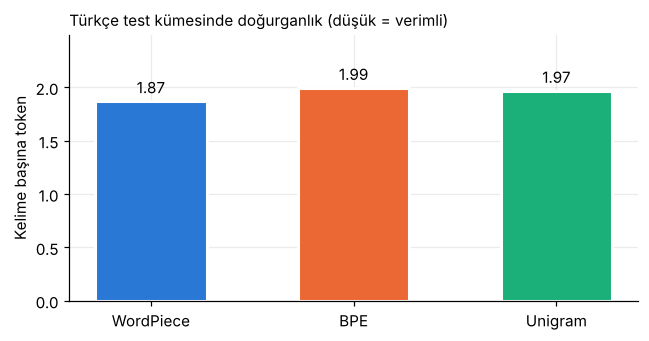

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.2))
adlar = list(sonuclar)
cubuklar = ax.bar(adlar, [sonuclar[a] for a in adlar], color=[RENK[a] for a in adlar],
                  width=0.55, edgecolor="white", linewidth=2)
ax.bar_label(cubuklar, fmt="%.2f", padding=3)
ax.set_ylabel("Kelime başına token")
ax.set_title("Türkçe test kümesinde doğurganlık (düşük = verimli)", fontsize=10, loc="left")
ax.set_ylim(0, max(sonuclar.values()) * 1.25)
plt.tight_layout(); plt.show()

In [12]:
# Aynı kelimeler üç algoritmada nasıl bölünüyor?
kelimeler = ["kitaplarımızdan", "gidiyorum", "güzelleştirilmiş", "Türkiye'nin", "öğretmenlerimizden"]
print(f"{'Kelime':20} | {'WordPiece':38} | {'BPE':38} | Unigram")
for k in kelimeler:
    wp = wp_tok.encode(k, add_special_tokens=False).tokens
    bp = okunur(bpe_tok, k)
    un = uni_tok.encode(k, add_special_tokens=False).tokens
    print(f"{k:20} | {str(wp):38} | {str(bp):38} | {un}")

Kelime               | WordPiece                              | BPE                                    | Unigram
kitaplarımızdan      | ['kitapları', '##mızdan']              | ['k', 'itap', 'larımız', 'dan']        | ['▁kitap', 'larımız', 'dan']
gidiyorum            | ['gidiyor', '##um']                    | ['gi', 'diyor', 'um']                  | ['▁gidiyor', 'um']
güzelleştirilmiş     | ['güzel', '##leştir', '##ilmiş']       | ['g', 'üzel', 'leştir', 'ilmiş']       | ['▁güzel', 'leştir', 'ilmiş']
Türkiye'nin          | ['türkiye', "'", 'nin']                | ['Türkiye', "'", 'nin']                | ['▁Türkiye', "'nin"]
öğretmenlerimizden   | ['öğretmen', '##lerimiz', '##den']     | ['öğr', 'etmen', 'lerimiz', 'den']     | ['▁öğretmen', 'lerimiz', 'den']


**Gözlem:** Üç algoritma da Türkçe ekleri (`-lar`, `-ımız`, `-dan` gibi) büyük ölçüde ayrı parçalar olarak öğrenir. WordPiece devam parçalarını `##` ile işaretler, BPE boşluğu token'ın içine (`Ġ`) gömer, Unigram ise kelime başını `▁` ile gösterir. Bu fark, kursun 6.5 kısmındaki genel bakış tablosunun uygulamadaki karşılığıdır.

## 8. Hızlı tokenizer'ın süper güçleri: offset ve kelime eşleme

Hızlı (Rust tabanlı) tokenizer'lar, her token'ın orijinal metindeki **karakter aralığını (offset)** takip eder. Bu sayede normalizasyon metni değiştirse bile (örneğin `İ` → `i`), her token'ı orijinal metindeki karşılığına geri eşleyebiliriz. Kursun 6.3 kısmındaki `word_ids()`, `word_to_chars()` ve `char_to_token()` metotlarını Türkçe bir cümlede deneyelim.

In [13]:
metin = "İSTANBUL'da Boğaziçi Üniversitesi'ni ziyaret ettik."
enc = wp_tok.encode(metin)

print(f"{'idx':>3} {'token':16} {'kelime':>6}  orijinal metindeki karşılığı")
for i, (t, w, (b, s)) in enumerate(zip(enc.tokens, enc.word_ids, enc.offsets)):
    print(f"{i:>3} {t:16} {str(w):>6}  {metin[b:s]!r}")

idx token            kelime  orijinal metindeki karşılığı
  0 [CLS]              None  ''
  1 istanbul              0  'İSTANBUL'
  2 '                     1  "'"
  3 da                    2  'da'
  4 boğaz                 3  'Boğaz'
  5 ##iç                  3  'iç'
  6 ##i                   3  'i'
  7 üniversitesi          4  'Üniversitesi'
  8 '                     5  "'"
  9 ni                    6  'ni'
 10 ziyaret               7  'ziyaret'
 11 ettik                 8  'ettik'
 12 .                     9  '.'
 13 [SEP]              None  ''


In [14]:
# 3 numaralı kelimenin (Boğaziçi) orijinal metindeki karakter aralığı
bas, son = enc.word_to_chars(3)
print("word_to_chars(3)  ->", (bas, son), "->", repr(metin[bas:son]))

# Orijinal metindeki 15. karakter hangi token'ın içinde?
k = 15
print(f"char_to_token({k}) ->", enc.char_to_token(k), "->", enc.tokens[enc.char_to_token(k)], f"(karakter: {metin[k]!r})")

word_to_chars(3)  -> (12, 20) -> 'Boğaziçi'
char_to_token(15) -> 4 -> boğaz (karakter: 'a')


**Gözlem:** Normalizer `İSTANBUL` kelimesini `istanbul`'a çevirmesine rağmen offset `(0, 8)` olarak orijinal `İSTANBUL` dizisini doğru şekilde gösterir. Normalizasyonu tokenizer'ın **dışında** (örneğin Python'un `.lower()` metoduyla) yaparsanız bu hizalama bozulur. Bunun ölçümü red-team raporundaki **Test 5**'tedir.

## 9. 🤗 Transformers'a sarmalama, padding ve stride

Kendi tokenizer'ımızı 🤗 Transformers'ta kullanmak için `PreTrainedTokenizerFast` ile sarmalıyoruz (6.9). Ardından toplu kodlama (batch encoding), dolgu (padding) ve kursun soru cevaplama kısmında (6.4) gördüğümüz **örtüşmeli parçalara bölme** (`stride`) özelliklerini deniyoruz.

In [15]:
from transformers import PreTrainedTokenizerFast

tr_tokenizer = PreTrainedTokenizerFast(
    tokenizer_object=wp_tok,
    unk_token="[UNK]", pad_token="[PAD]", cls_token="[CLS]", sep_token="[SEP]", mask_token="[MASK]",
)
print("Hızlı tokenizer mı? is_fast =", tr_tokenizer.is_fast)

grup = ["Merhaba dünya!", "Bu cümle diğerinden biraz daha uzun bir cümledir."]
batch = tr_tokenizer(grup, padding=True)
for ids, mask in zip(batch["input_ids"], batch["attention_mask"]):
    print(tr_tokenizer.convert_ids_to_tokens(ids))
    print("  attention_mask:", mask)

Hızlı tokenizer mı? is_fast = True
['[CLS]', 'merha', '##ba', 'dünya', '!', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
  attention_mask: [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0]
['[CLS]', 'bu', 'cümle', 'diğer', '##inden', 'biraz', 'daha', 'uzun', 'bir', 'cümle', '##dir', '.', '[SEP]']
  attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [16]:
# Uzun bir metni en fazla 12 token'lık, 4 token örtüşmeli parçalara bölme (QA pipeline'ındaki yöntem)
uzun = "Türkçe eklemeli bir dildir ve bir kelimeye art arda pek çok ek gelebilir; bu da tokenizer seçimini önemli kılar."
parcalar = tr_tokenizer(uzun, max_length=12, stride=4, truncation=True, return_overflowing_tokens=True)
for ids in parcalar["input_ids"]:
    print(tr_tokenizer.convert_ids_to_tokens(ids))
print("overflow_to_sample_mapping:", parcalar["overflow_to_sample_mapping"])

['[CLS]', 'türkçe', 'eklem', '##eli', 'bir', 'dil', '##dir', 've', 'bir', 'kelime', '##ye', '[SEP]']
['[CLS]', 've', 'bir', 'kelime', '##ye', 'art', 'ard', '##a', 'pek', 'çok', 'ek', '[SEP]']
['[CLS]', '##a', 'pek', 'çok', 'ek', 'gelebilir', ';', 'bu', 'da', 'tok', '##eniz', '[SEP]']
['[CLS]', 'bu', 'da', 'tok', '##eniz', '##er', 'seçim', '##ini', 'önemli', 'kıl', '##ar', '[SEP]']
['[CLS]', '##ini', 'önemli', 'kıl', '##ar', '.', '[SEP]']
overflow_to_sample_mapping: [0, 0, 0, 0, 0]


In [17]:
# Kaydet ve yeniden yükle
tr_tokenizer.save_pretrained("turkce-wordpiece-tokenizer")
print(sorted(os.listdir("turkce-wordpiece-tokenizer")))

from transformers import AutoTokenizer
yeniden = AutoTokenizer.from_pretrained("turkce-wordpiece-tokenizer")
print("Yeniden yüklenen:", yeniden.tokenize("Kaydettiğimiz tokenizer'ı geri yükledik."))

['tokenizer.json', 'tokenizer_config.json']


Yeniden yüklenen: ['kaydetti', '##ğimiz', 'tok', '##eniz', '##er', "'", 'ı', 'geri', 'yük', '##ledi', '##k', '.']


## 10. (Opsiyonel) `train_new_from_iterator` ile GPT-2'den Türkçe tokenizer

Kursun 6.2 kısmındaki yöntem: GPT-2'nin İngilizce tokenizer'ını şablon olarak alıp Türkçe derlemde yeniden eğitiyoruz. Bu hücre GPT-2 tokenizer'ını **Hugging Face Hub**'dan indirdiği için internet bağlantısı gerektirir (Colab'da sorunsuz çalışır). Hub'a erişilemezse hücre hata vermeden atlanır.

In [18]:
try:
    eski = transformers.AutoTokenizer.from_pretrained("gpt2")
except Exception as hata:
    eski = None
    print("Hugging Face Hub'a erişilemedi, bu kısım atlandı:", type(hata).__name__)

if eski is not None:
    yeni = eski.train_new_from_iterator(get_training_corpus(), vocab_size=VOCAB)
    ornek = "Öğretmenlerimizden aldığımız ödevleri bitirdik."
    print("GPT-2 (İngilizce):", len(eski.tokenize(ornek)), "token")
    print("Türkçe yeniden eğitilmiş:", len(yeni.tokenize(ornek)), "token")
    print("İngilizce dağarcıkla doğurganlık :", round(sum(len(eski.tokenize(c)) for c in tr_test) / sum(len(c.split()) for c in tr_test), 2))
    print("Türkçe dağarcıkla doğurganlık   :", round(sum(len(yeni.tokenize(c)) for c in tr_test) / sum(len(c.split()) for c in tr_test), 2))

Hugging Face Hub'a erişilemedi, bu kısım atlandı: OSError


## Özet

- Türkçe derlemde üç algoritmayı da sıfırdan eğittik. Aynı kelime dağarcığı boyutunda üçü de kelime başına yaklaşık 2 token üretti ve Türkçe ekleri ayrı parçalar olarak öğrendi.
- Standart Unicode küçük harf kuralının Türkçe `I/İ` harflerini yanlış dönüştürdüğünü gördük ve bunu düzelten bir normalizer kurduk.
- Hızlı tokenizer'ın offset eşlemesi sayesinde normalizasyondan sonra bile token'ları orijinal metne doğru şekilde geri eşledik.
- Tokenizer'ı 🤗 Transformers'a sarmalayıp padding, stride, kaydetme ve yeniden yükleme işlemlerini uyguladık.

Bu tokenizer'ların nasıl "kırılabileceği" (İngilizce tokenizer'ın Türkçede çökmesi, harf çakışmaları, görünmez karakter saldırıları, offset kayması) **red-team** klasöründeki rapor ve notebook'ta ölçülmüştür.